In [22]:
import numpy as np
import pandas as pd
from scipy.special import hankel2
from scipy import integrate

from mesh.load_meshes import load_meshes
from mesh.gen_meshes import gen_meshes, Stadium
from mesh.plot_meshes import plot_meshes

from models import Nodes, Elements, Edges, Domain
from typing import Literal

from numpy.typing import NDArray

### Physical parameters + config

In [23]:
E0 = 1  # Plane wave amplitude
EPS0: float = 8.85e-12  # Diel. permittivity of vacuum
EPS1: float = 1.0  # Permittivity of air
MU0: float = 4 * np.pi * 1e-7  # Mag. permeability of vacuum
MU1: float = 1.0  # Permeability of the air
SIG1 = 0.0  # Conductivity of the air (S/m)
V = 1 / np.sqrt(EPS0 * MU0 * EPS1 * MU1)  # wave speed
F_HZ = 4e9  # Plane wave frequency
OMEGA = 2 * np.pi * F_HZ  # Angular frequency
LAMBDA = V / F_HZ  # Wavelength
K0: float = 2 * np.pi / LAMBDA  # Free space wave number
KPW = np.array([0, -K0])  # Direction of the plane wave

# Router
I = 1  # Amps
SRC: Literal["plane_wave", "router"] = "plane_wave"
rs = np.array([-0.1, -0.1])  # Router placement

### Mesh

Define shapes and generate the mesh using GMSH

2626 nodes, 5090 triangles -> mesh
2626 nodes, 5090 triangles
  AIR         4818 triangles
  METAL        272 triangles
element size h: min 0.003701, median 0.009977, max 0.01347 m


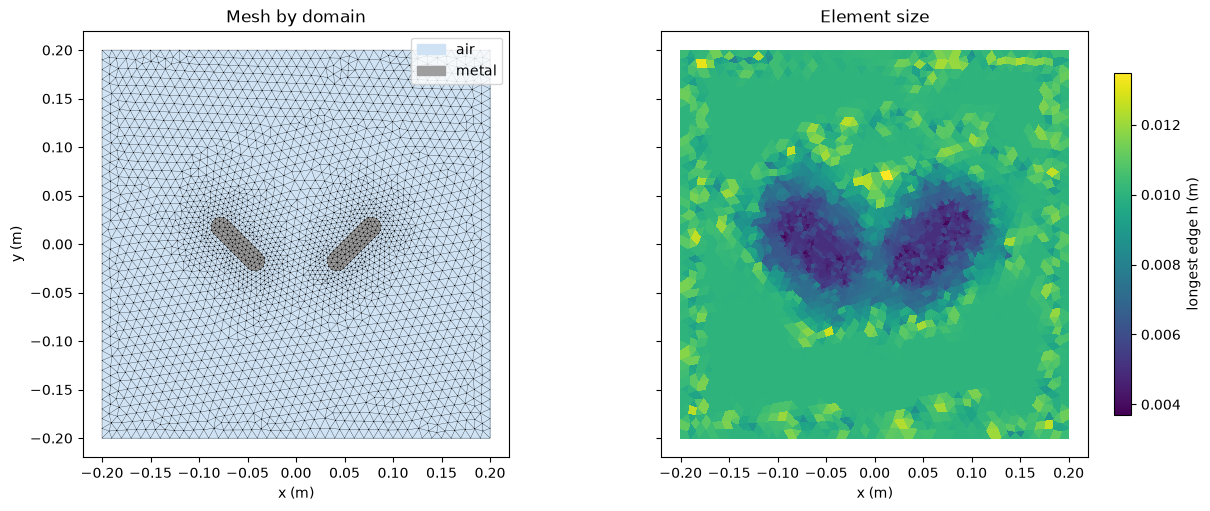

In [24]:
mesh_dir = "mesh"

gen_meshes(
    box=(-0.2, -0.2, 0.2, 0.2),
    shapes=[
        Stadium(
            x=0.06,
            y=-0.0,
            length=0.05,
            r=0.01,
            angle=np.pi / 4,
            domain=Domain.METAL,
        ),
        Stadium(
            x=-0.06,
            y=0.0,
            length=0.05,
            r=0.01,
            angle=3 * np.pi / 4,
            domain=Domain.METAL,
        ),
    ],
    h_far=0.01,
    h_shape=0.005,
    out_dir=mesh_dir,
)

nodes, elements = load_meshes(src_dir=mesh_dir)
plot_meshes(nodes=nodes, elements=elements)

### Compute Boundary Elements 

In [25]:
def find_boundary_edges(elements: Elements, domain: Domain) -> Edges:
    """Edges on border of Domain.AIR to domain."""
    assert domain != Domain.AIR, "Can't find boundary of air to air"

    air = elements[elements.domains == Domain.AIR].node_idxs  # (T, 3)
    obj = elements[elements.domains == domain].node_idxs  # (T, 3)

    assert obj.shape[0] > 0, f"No objects of domain {domain}"

    def _els_to_edges(el: NDArray) -> NDArray:
        # Triangle [a, b, c] -> edges (a,b), (b,c), (c,a)
        return np.concatenate([el[:, [0, 1]], el[:, [1, 2]], el[:, [2, 0]]])  # (3T, 2)

    obj_edges = _els_to_edges(obj)
    air_edges = _els_to_edges(air)

    # object edge n1->n2 is on boundary to air if air_edges also has n2->n1
    air_edge_set = {tuple(sorted(e)) for e in air_edges.tolist()}
    is_boundary = np.array(
        [tuple(sorted(e)) in air_edge_set for e in obj_edges.tolist()],
        dtype=bool,
    )

    return Edges(node_idxs=obj_edges[is_boundary])


pec_edges: Edges = find_boundary_edges(elements, domain=Domain.METAL)

# Nodes on the PEC edges
is_pec_node = np.zeros(nodes.xy.shape[0], dtype=bool)
is_pec_node[np.unique(pec_edges.node_idxs)] = True

### Prepare K@x=b

In [26]:
def green_sca_2d(r: NDArray, rp: NDArray) -> NDArray[np.complexfloating]:
    # assert r.shape[-1] == 2 and rp.shape[-1] == 2
    return -1j / 4 * hankel2(0, K0 * np.linalg.norm(r - rp, axis=-1))


def line_path(r1: NDArray, r2: NDArray, t: float) -> NDArray[np.floating]:
    # assert 0 <= t and t <= 1
    return r1 + t * (r2 - r1)


def plane_wave(r: NDArray) -> NDArray[np.complexfloating]:
    return E0 * np.exp(-1j * np.dot(r, KPW))


def cylindrical_wave(r: NDArray, rs: NDArray) -> NDArray[np.complexfloating]:
    return -OMEGA * MU0 * MU1 / 4.0 * I * green_sca_2d(r, rs)

In [27]:
P = nodes.xy.shape[0]  # number of mesh nodes (observation points)
N = pec_edges.node_idxs.shape[0]  # number of boundary elements


K = np.zeros((N, N), dtype=complex)
b = np.zeros((N, 1), dtype=complex)

pec_xy: NDArray[np.floating] = nodes.xy[pec_edges.node_idxs]  # (N, 2 ends, 2 coords)

# Vectors
d = pec_xy[:, 1, :] - pec_xy[:, 0, :]  # edge vector
r = pec_xy.mean(axis=1)  # edge center (N, 2 coords)
# n = np.stack([d[:, 1], -d[:, 0]], axis=1)  # edge normal vector


# Kij = integral(G) along Lj,
for i in range(N):  # observation point
    for j in range(N):  # source point
        Lj = np.linalg.norm(d[j, :])

        # split in two for singularity at integration edges
        i1, i1_err = integrate.quad(
            lambda t: Lj
            * green_sca_2d(line_path(pec_xy[j, 0, :], pec_xy[j, 1, :], t), r[i, :]),
            a=0.0,
            b=0.5,
            complex_func=True,
        )

        i2, i2_err = integrate.quad(
            lambda t: Lj
            * green_sca_2d(line_path(pec_xy[j, 0, :], pec_xy[j, 1, :], t), r[i, :]),
            a=0.5,
            b=1.0,
            complex_func=True,
        )

        K[i, j] = i1 + i2

# Incoming field
if SRC == "plane_wave":
    b = plane_wave(r)  # (P,)
else:
    b = cylindrical_wave(r=r, rs=rs)

### Solve that shi

In [28]:
dEz_n = np.linalg.solve(K, b)

### Compute outputs $E_{sca}$ and $E_{tot}$

In [29]:
Lj = np.linalg.norm(d, axis=1)  # (N,) edge lengths

Esca = np.zeros(P, dtype=complex)
if SRC == "plane_wave":
    Esrc = plane_wave(nodes.xy)
else:
    Esrc = cylindrical_wave(r=nodes.xy, rs=rs)

for p in range(P):
    # PEC nodes: use boundary condition: E_tot = 0, so Esca = -Esrc
    if is_pec_node[p]:
        Esca[p] = -Esrc[p]
        continue

    Esca[p], Esca_err = integrate.quad(
        lambda t: -1
        * np.sum(
            Lj
            * green_sca_2d(
                r=nodes.xy[p, :],
                rp=line_path(r1=pec_xy[:, 0, :], r2=pec_xy[:, 1, :], t=t),
            )
            * dEz_n
        ),
        a=0.0,
        b=1.0,
        complex_func=True,
    )

Etot = Esrc + Esca

### Field plot

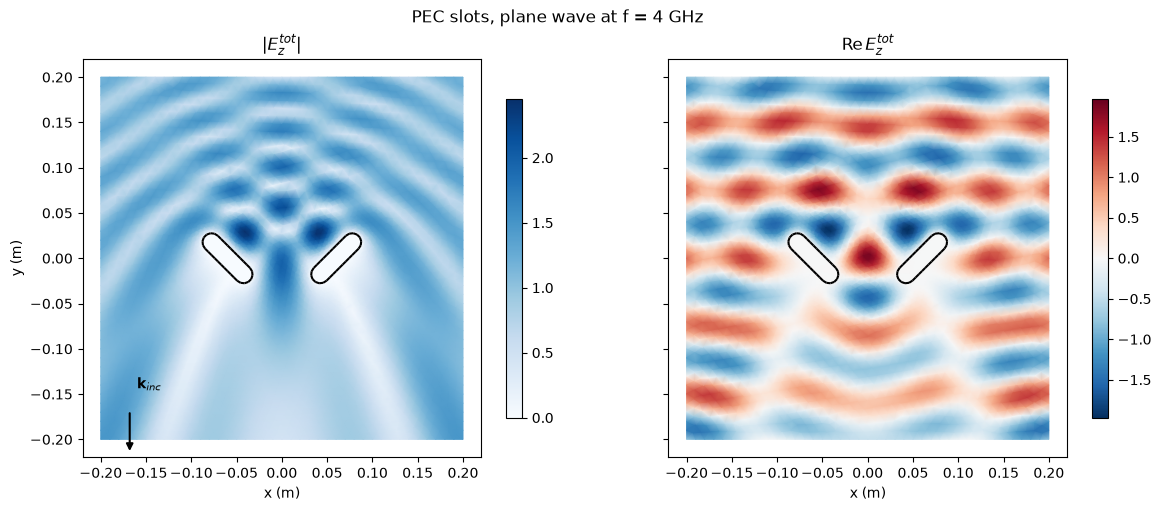

In [30]:
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.tri import Triangulation

tri = Triangulation(nodes.xy[:, 0], nodes.xy[:, 1], elements.node_idxs)
re_max = np.abs(Etot.real).max()  # symmetric limits so 0 sits at the neutral midpoint

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True, layout="constrained")
panels = [
    (axes[0], np.abs(Etot), "Blues", dict(vmin=0), r"$|E_z^{tot}|$"),
    (
        axes[1],
        Etot.real,
        "RdBu_r",
        dict(vmin=-re_max, vmax=re_max),
        r"$\mathrm{Re}\,E_z^{tot}$",
    ),
]
for ax, field, cmap, lims, label in panels:
    im = ax.tripcolor(tri, field, shading="gouraud", cmap=cmap, **lims)
    # PEC outlines (the slots are holes in the mesh)
    ax.add_collection(LineCollection(list(pec_xy), colors="black", linewidths=1.5))
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.set_title(label)
    fig.colorbar(im, ax=ax, shrink=0.8)
axes[0].set_ylabel("y (m)")

# Direction of the incident plane wave
k_hat = KPW / np.linalg.norm(KPW)
x0, y0 = nodes.xy.min(axis=0)
span = np.ptp(nodes.xy, axis=0).min()
axes[0].annotate(
    "",
    xy=(
        x0 + 0.08 * span + 0.12 * span * k_hat[0],
        y0 + 0.08 * span + 0.12 * span * k_hat[1],
    ),
    xytext=(x0 + 0.08 * span, y0 + 0.08 * span),
    arrowprops=dict(arrowstyle="-|>", color="black", lw=1.5),
)
axes[0].text(x0 + 0.1 * span, y0 + 0.14 * span, r"$\mathbf{k}_{inc}$")

fig.suptitle(f"PEC slots, plane wave at f = {F_HZ / 1e9:.0f} GHz")
plt.show()

### Power plot

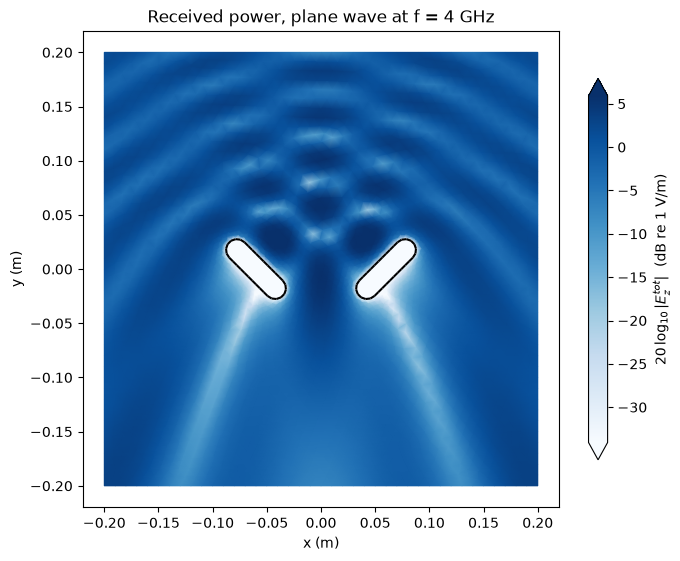

In [31]:
# Power density goes as |E|^2, so in dB: 10*log10(|E|^2) = 20*log10(|E|).
# Fixed reference (1 V/m) rather than normalising to the max, so plots from
# different router positions / frequencies share one scale.
E_FLOOR = 1e-12  # |E_tot| = 0 on the PEC walls; clip so log10 stays finite
power_db = 20 * np.log10(np.maximum(np.abs(Etot), E_FLOOR))

# Nodes right next to the router are huge (log singularity of H0), so a
# percentile instead of the max sets the top of the colour scale; those few
# nodes just saturate. Show a fixed dynamic range below it.
DYN_RANGE_DB = 40
p_max = np.percentile(power_db, 99)
p_min = p_max - DYN_RANGE_DB

fig, ax = plt.subplots(figsize=(7, 5.5), layout="constrained")
im = ax.tripcolor(
    tri, power_db, shading="gouraud", cmap="Blues", vmin=p_min, vmax=p_max
)
ax.add_collection(LineCollection(list(pec_xy), colors="black", linewidths=1.5))
if SRC == "router":
    ax.plot(*rs, ls="none", marker="o", ms=8, mfc="white", mec="black", label="router")
    ax.legend(loc="upper right")
ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title(f"Received power, {SRC.replace('_', ' ')} at f = {F_HZ / 1e9:.0f} GHz")
cbar = fig.colorbar(im, ax=ax, shrink=0.8, extend="both")
cbar.set_label(r"$20\,\log_{10}|E_z^{tot}|$  (dB re 1 V/m)")
plt.show()